# Supplementary Figure 3: CAMPI member support and identity recovery

The figure shows, for the 15 CAMPI mock-community acquisitions, how many peptides specific to each of the eight community members the FastaLake (FL) search accepted (a, b), how many of the reference-database peptide identities each Sage search arm recovered within the same acquisition (c), and the same recovery measured inside a second search engine, MSFragger with Percolator (d). Every value is read from `source_data/SFig03/`; the tables for panels a to c are also recounted from the per-acquisition peptide membership tables.

Run from the repository root: `python paper.py build SFig03`.

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()

from IPython.display import Image, display
import pandas as pd
pd.set_option("display.width", 160)
HAVE_FONT = panels.init()          # producer rcParams (start from matplotlib defaults) and Söhne Buch if present
print("Söhne Buch found:", HAVE_FONT)
t = panels.load(SD)
print({k: v.shape for k, v in t.items()})

Söhne Buch found: True
{'support': (80, 6), 'acq_counts': (1200, 5), 'recovery': (150, 10), 'msfragger': (60, 10), 'between_engine': (90, 9), 'receipts': (45, 10)}


## Composite

The four panels share one layout (160 x 140 mm at placed size), so they are drawn together. Two steps, as for the v30 figure. First the producer (`build_figure`, matplotlib with the producer's rcParams) draws a-d with panels c,d at 9-50 residues (the len950 rebuild; the v28f figure drew c,d at 5-50), the PDF is saved, the 16 taxon labels are re-set with a synthetic slant (the published label edit) and the page is rasterised at 400 dpi; each panel section below cuts its panel out of this render for display. Second, `build_v30` (section v30 house style) redraws the same values in the house style and proves them identical.

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


slanted labels: 16 | smallest text at placed size (pt): 5.25 | PNG px: (2520, 2205)


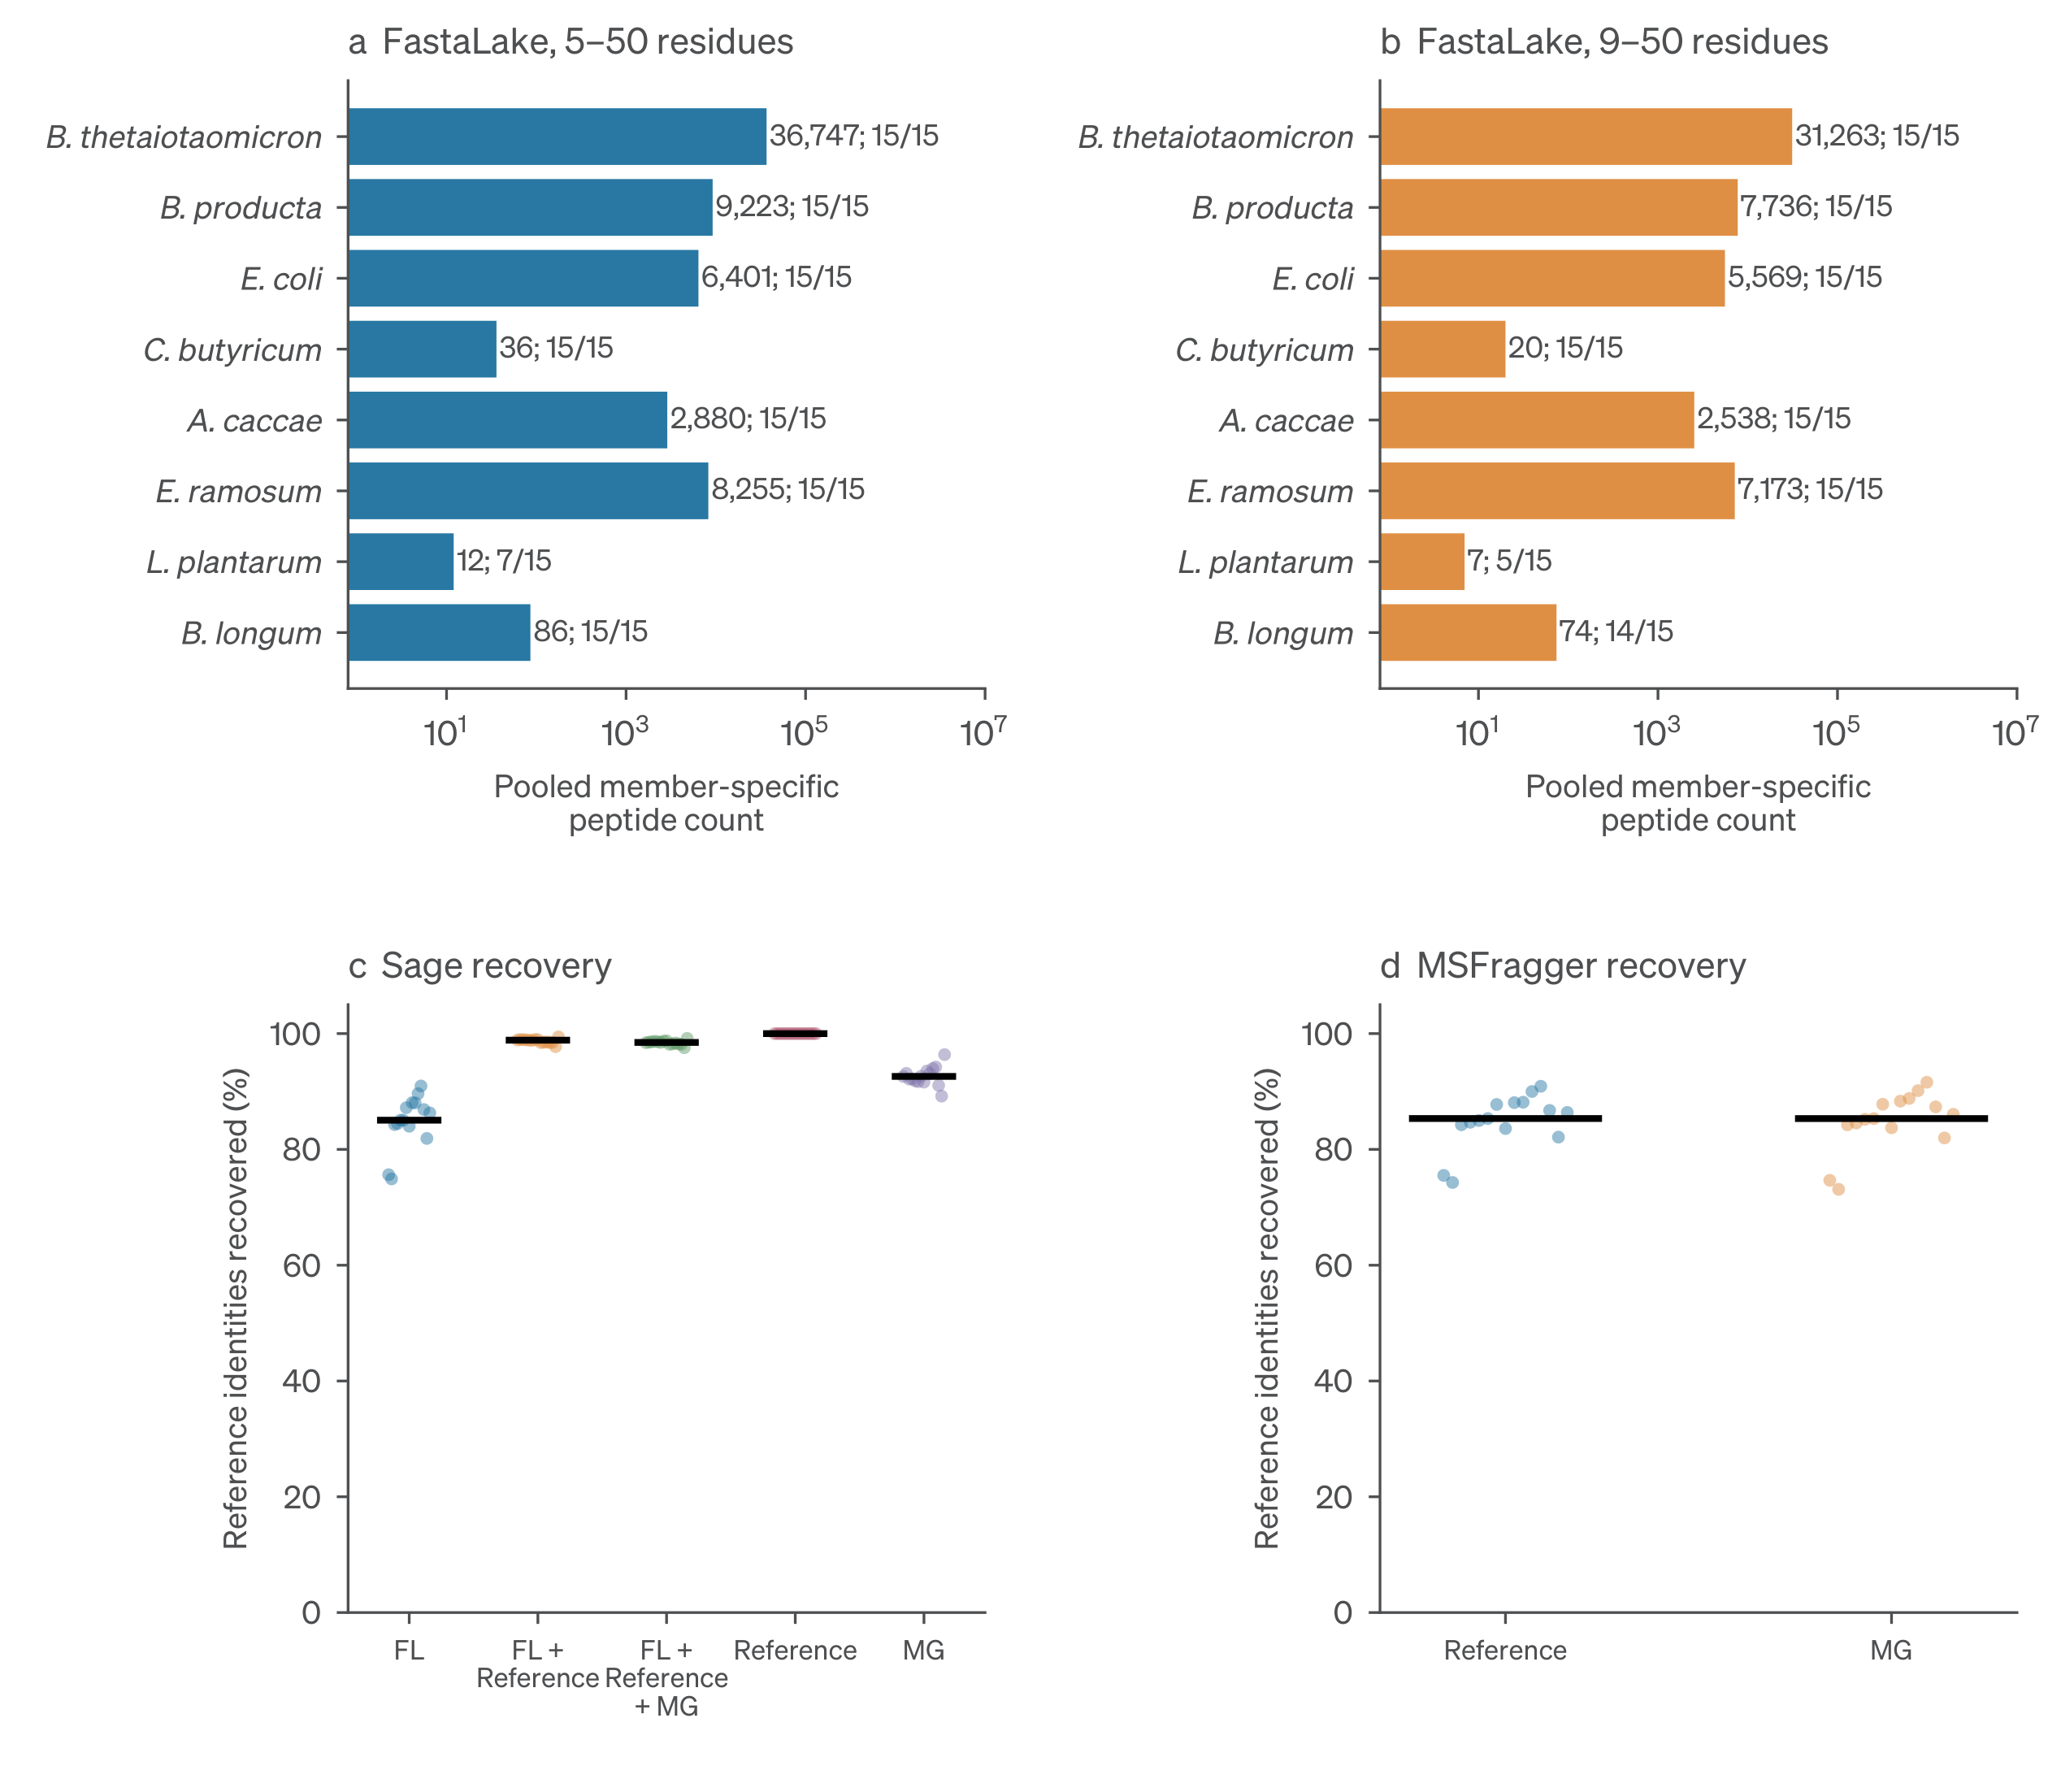

In [2]:
fig, axes, plotted = panels.build_figure(t)
res = panels.save_figure(fig, t, OUT)
plotted.to_csv(OUT / "plotted_values.tsv", sep="\t", index=False)
print("slanted labels:", res["slanted"], "| smallest text at placed size (pt):", res["smallest_text_pt"], "| PNG px:", res["png_px"])
display(Image(filename=str(res["png"]), width=760))

## Panel a

Pooled member-specific peptide counts in the FL arm at 5-50 residues, labelled with the count and the number of acquisitions (of 15) contributing at least one such peptide. Supports: "FastaLake recovered member-specific peptides for all eight community members, including the least represented, Lactiplantibacillus plantarum (twelve pooled peptides at 5–50 residues ...)" (v28d line 83; v30 cites Supplementary Figs. 3,4 for the same member support). n = 15 acquisitions; counts are distinct peptides pooled over acquisitions. No test.

The three published tables behind panels a to c are first recounted from the 15 accepted-peptide membership tables (one per acquisition, all five Sage arms).

{'equal_support': True, 'equal_acq_counts': True, 'equal_recovery': True, 'lengths_in_window': True}
{'n_members': 8, 'n_members_total': 8, 'lp_fl_5': 12, 'lp_fl_9': 7, 'mg_members_9': 6, 'mg_zero_9': ['Bifidobacterium longum', 'Lactobacillus plantarum'], 'least3': ['Lactobacillus plantarum', 'Clostridium butyricum', 'Bifidobacterium longum'], 'fold_ref_over_fl': {'Lactobacillus plantarum': 16.75, 'Clostridium butyricum': 12.027777777777779, 'Bifidobacterium longum': 3.372093023255814}, 'fold_min': 3.372093023255814, 'fold_max': 16.75, 'flr_exceeds_ref': {'Lactobacillus plantarum': True, 'Clostridium butyricum': True, 'Bifidobacterium longum': True}}


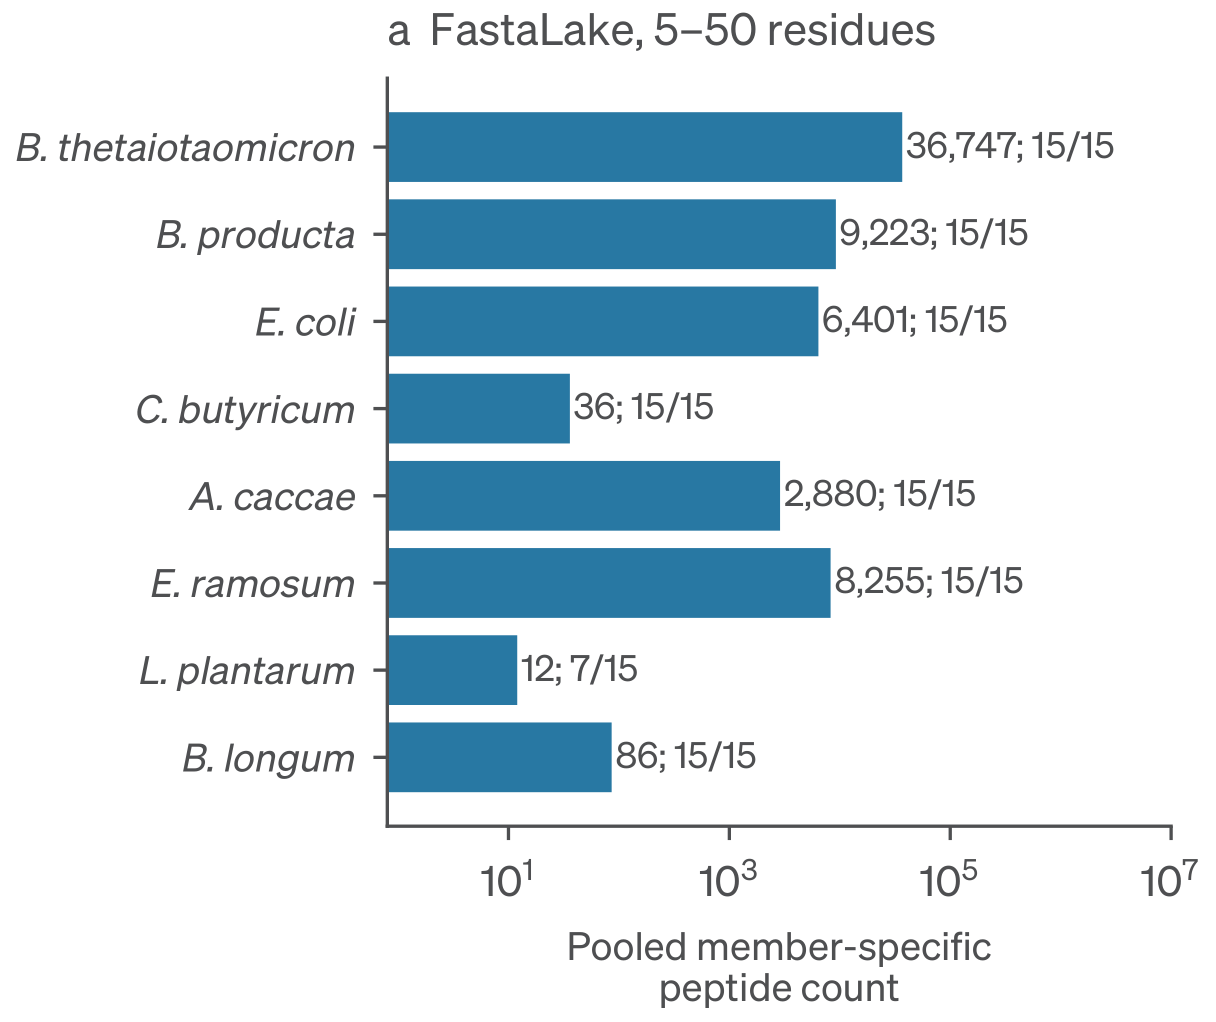

In [3]:
rc = panels.stat_recount_membership(SD, t)
print({k: v for k, v in rc.items() if k.startswith(("equal", "lengths"))})
assert rc["equal_support"] and rc["equal_acq_counts"] and rc["equal_recovery"] and rc["lengths_in_window"]
s83 = panels.stat_line83_member_support(t)
print(s83)
panels.crop(res["png"], panels.CROP_BOXES["a"], OUT / "panel_a.png")
panels.crop_pdf(res["pdf"], panels.CROP_BOXES["a"], OUT / "panel_a.pdf")
display(Image(filename=str(OUT / "panel_a.png"), width=380))

## Panel b

As panel a for the nested 9-50-residue subset, which keeps the q values of the 5-50 search. Supports "... and seven at 9–50 residues" and, with the MG rows of the same table, "At 9–50 residues, the metagenome database recovered member-specific peptides for only six members, with none for L. plantarum or Bifidobacterium longum" (v28d line 83). n = 15 acquisitions. No test.

MG members with none at 9-50: ['Bifidobacterium longum', 'Lactobacillus plantarum']
REF/FL pooled-count fold (5-50) for the three least represented members: {'Lactobacillus plantarum': 16.75, 'Clostridium butyricum': 12.027777777777779, 'Bifidobacterium longum': 3.372093023255814}
FL + Reference exceeds REF for these members: {'Lactobacillus plantarum': True, 'Clostridium butyricum': True, 'Bifidobacterium longum': True}


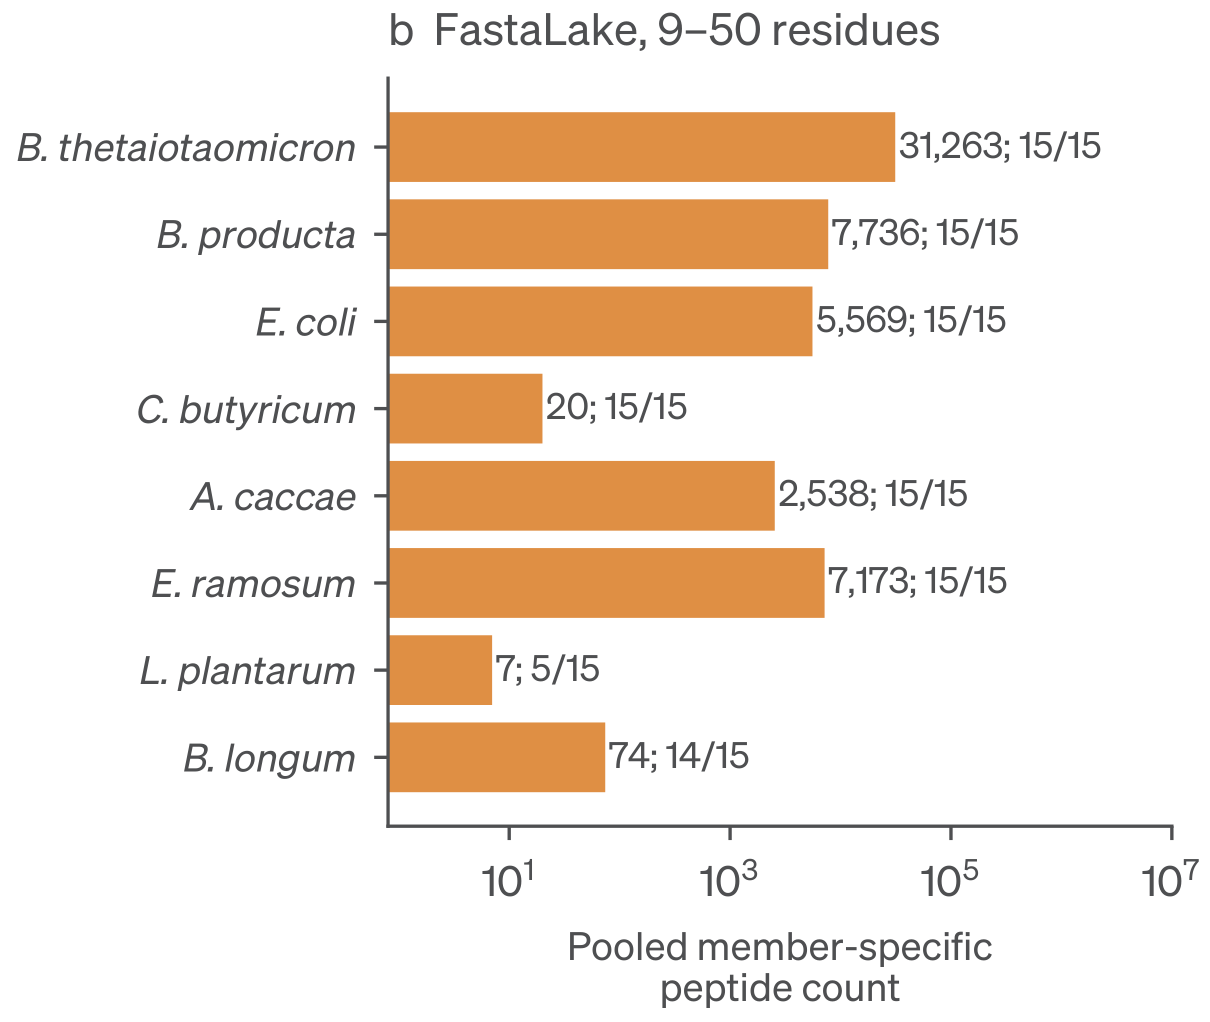

In [4]:
print("MG members with none at 9-50:", s83["mg_zero_9"])
print("REF/FL pooled-count fold (5-50) for the three least represented members:", s83["fold_ref_over_fl"])
print("FL + Reference exceeds REF for these members:", s83["flr_exceeds_ref"])
panels.crop(res["png"], panels.CROP_BOXES["b"], OUT / "panel_b.png")
panels.crop_pdf(res["pdf"], panels.CROP_BOXES["b"], OUT / "panel_b.pdf")
display(Image(filename=str(OUT / "panel_b.png"), width=380))

## Panel c

Within-acquisition recovery of reference (REF) peptide identities by each Sage arm at 9-50 residues (the nested 9-50 rows of the accepted 5-50 lists, original q values): |arm ∩ REF| / |REF|. Dots are acquisitions (n = 15 per arm), bars are medians. Legend: "c,d use peptides of 9–50 residues" (v30; v28d line 417). No test.

panel    arm  n  median_percent
    c     FL 15       85.047094
    c   FL_R 15       98.863228
    c FL_R_M 15       98.475209
    c    REF 15      100.000000
    c     MG 15       92.603955
    d    REF 15       85.330534
    d     MG 15       85.324277


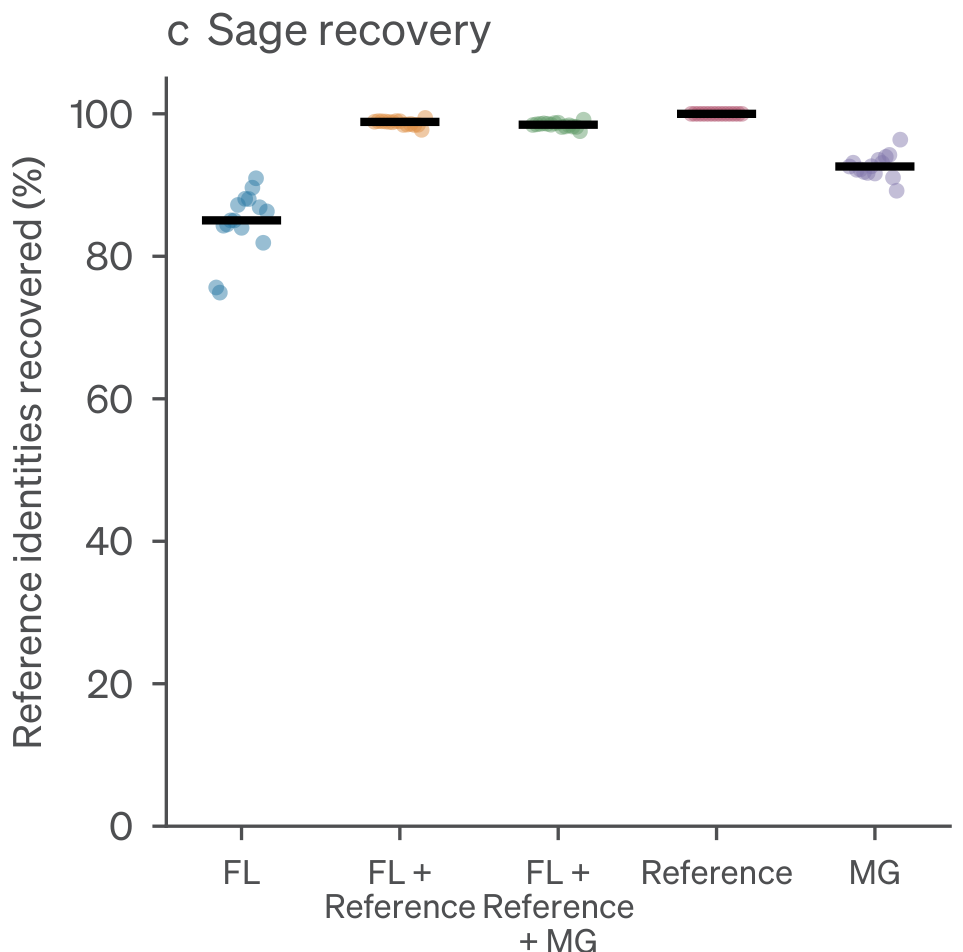

In [5]:
med = panels.stat_panel_medians(plotted)
print(med.to_string(index=False))
panels.crop(res["png"], panels.CROP_BOXES["c"], OUT / "panel_c.png")
panels.crop_pdf(res["pdf"], panels.CROP_BOXES["c"], OUT / "panel_c.pdf")
display(Image(filename=str(OUT / "panel_c.png"), width=380))

## Panel d

Within-MSFragger recovery of REF and MG identities by FastaLake at 9-50 residues (MSFragger 4.1, Percolator 3.06.5, peptide q ≤ 0.01 per acquisition). Dots are acquisitions (n = 15 per comparator), bars are medians. Supports "In CAMPI, FastaLake yielded as many peptides as the reference database (median ratio 1.00) and 0.94 times as many as MG, while recovering a median 85.3% of comparator peptide identities (Supplementary Fig. 3)" (v30; v28d line 89 printed 0.99, 0.94 and 84.6% at 5-50 residues). Descriptive medians; no test. The table is checked against the accepted counts written by each of the 45 searches.

{'n_REF': 15, 'ratio_REF': 1.0028744939271257, 'recovery_REF': 0.8533053440546503, 'fl_more_REF': 8, 'n_MG': 15, 'ratio_MG': 0.9444444444444444, 'recovery_MG': 0.8532427709452999, 'fl_more_MG': 0, 'recovery_pooled': 0.8532740574999751}
{'n_searches': 45, 'n_acquisitions': 15, 'all_pass': True, 'engine_strings': ['MSFragger 4.1; independent per-acquisition Percolator 3.06.5 target-decoy competition, peptide q <=0.01'], 'msfragger_version': '4.1', 'percolator_version': '3.06.5', 'counts_match': True}


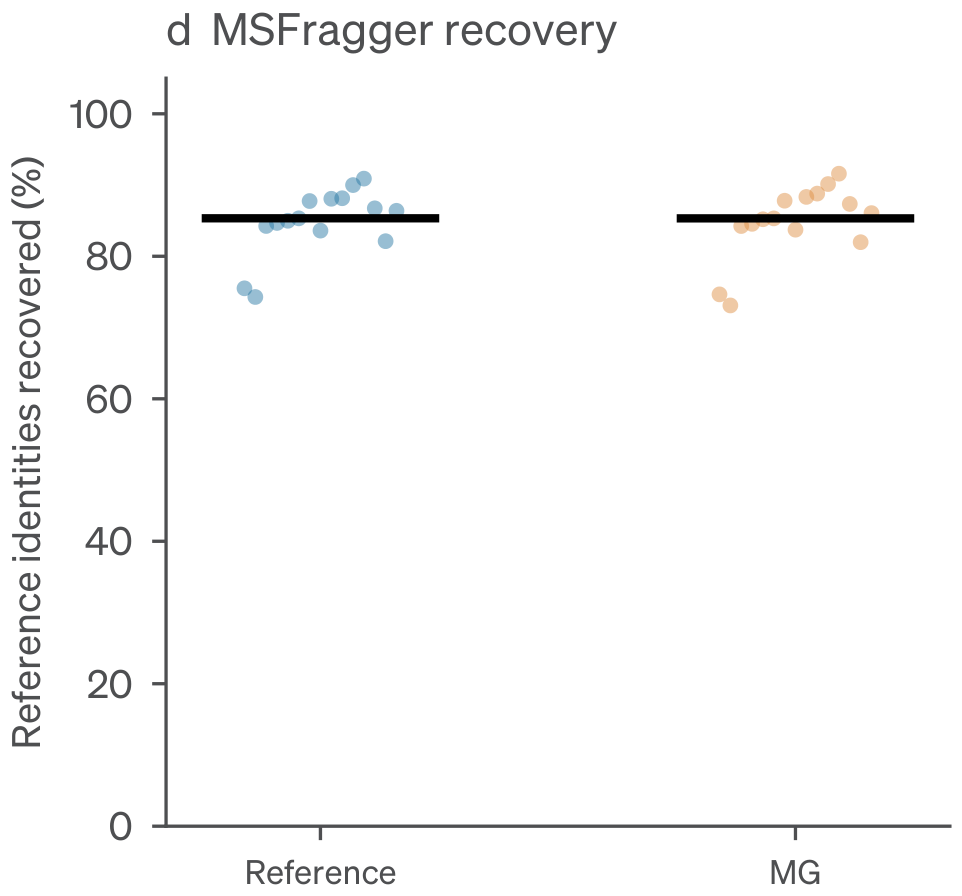

In [6]:
s89 = panels.stat_line89_msfragger(t)
print(s89)
rcpt = panels.stat_msfragger_receipts(t)
print(rcpt)
assert rcpt["counts_match"] and rcpt["all_pass"]
panels.crop(res["png"], panels.CROP_BOXES["d"], OUT / "panel_d.png")
panels.crop_pdf(res["pdf"], panels.CROP_BOXES["d"], OUT / "panel_d.pdf")
display(Image(filename=str(OUT / "panel_d.png"), width=380))

## v30 house style

The v30 figure redraws the same tables in the house style: Söhne type, ink, bold panel letters, arm colours as in main Figure 2 (FL blue, FL + Reference green, FL + Reference + MG reddish purple, Reference grey, MG orange), drawn at 160 x 140 mm. Subpanel titles move into the x-axis labels; c is widened and d narrowed. `build_v30` reruns the producer and asserts that every plotted array, limit and scale, the plotted-values table and the a,b value labels are identical.

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


<repo>/figures/SFig03/panels.py:974: UserWarning: _raw_SFig03_v30.pdf is 160.00 mm wide, not 88 or 180 mm (nearest 180). compose.py will refuse it. If it is a near miss, the cause is almost always a bbox that cropped the canvas -- REDRAW at the placed width; do not scale and do not pad.
  raw, _ = fl.save(fig, out / '_raw_SFig03_v30', formats=('pdf',))


v30 values identical: True | plotted table equal: True | value labels equal: True
label strings lost (titles only): ['Pooled member-specific\npeptide count', 'a  FastaLake, 5–50 residues', 'b  FastaLake, 9–50 residues', 'c  Sage recovery', 'd  MSFragger recovery'] | slanted labels: 16 | png px: (1890, 1654)


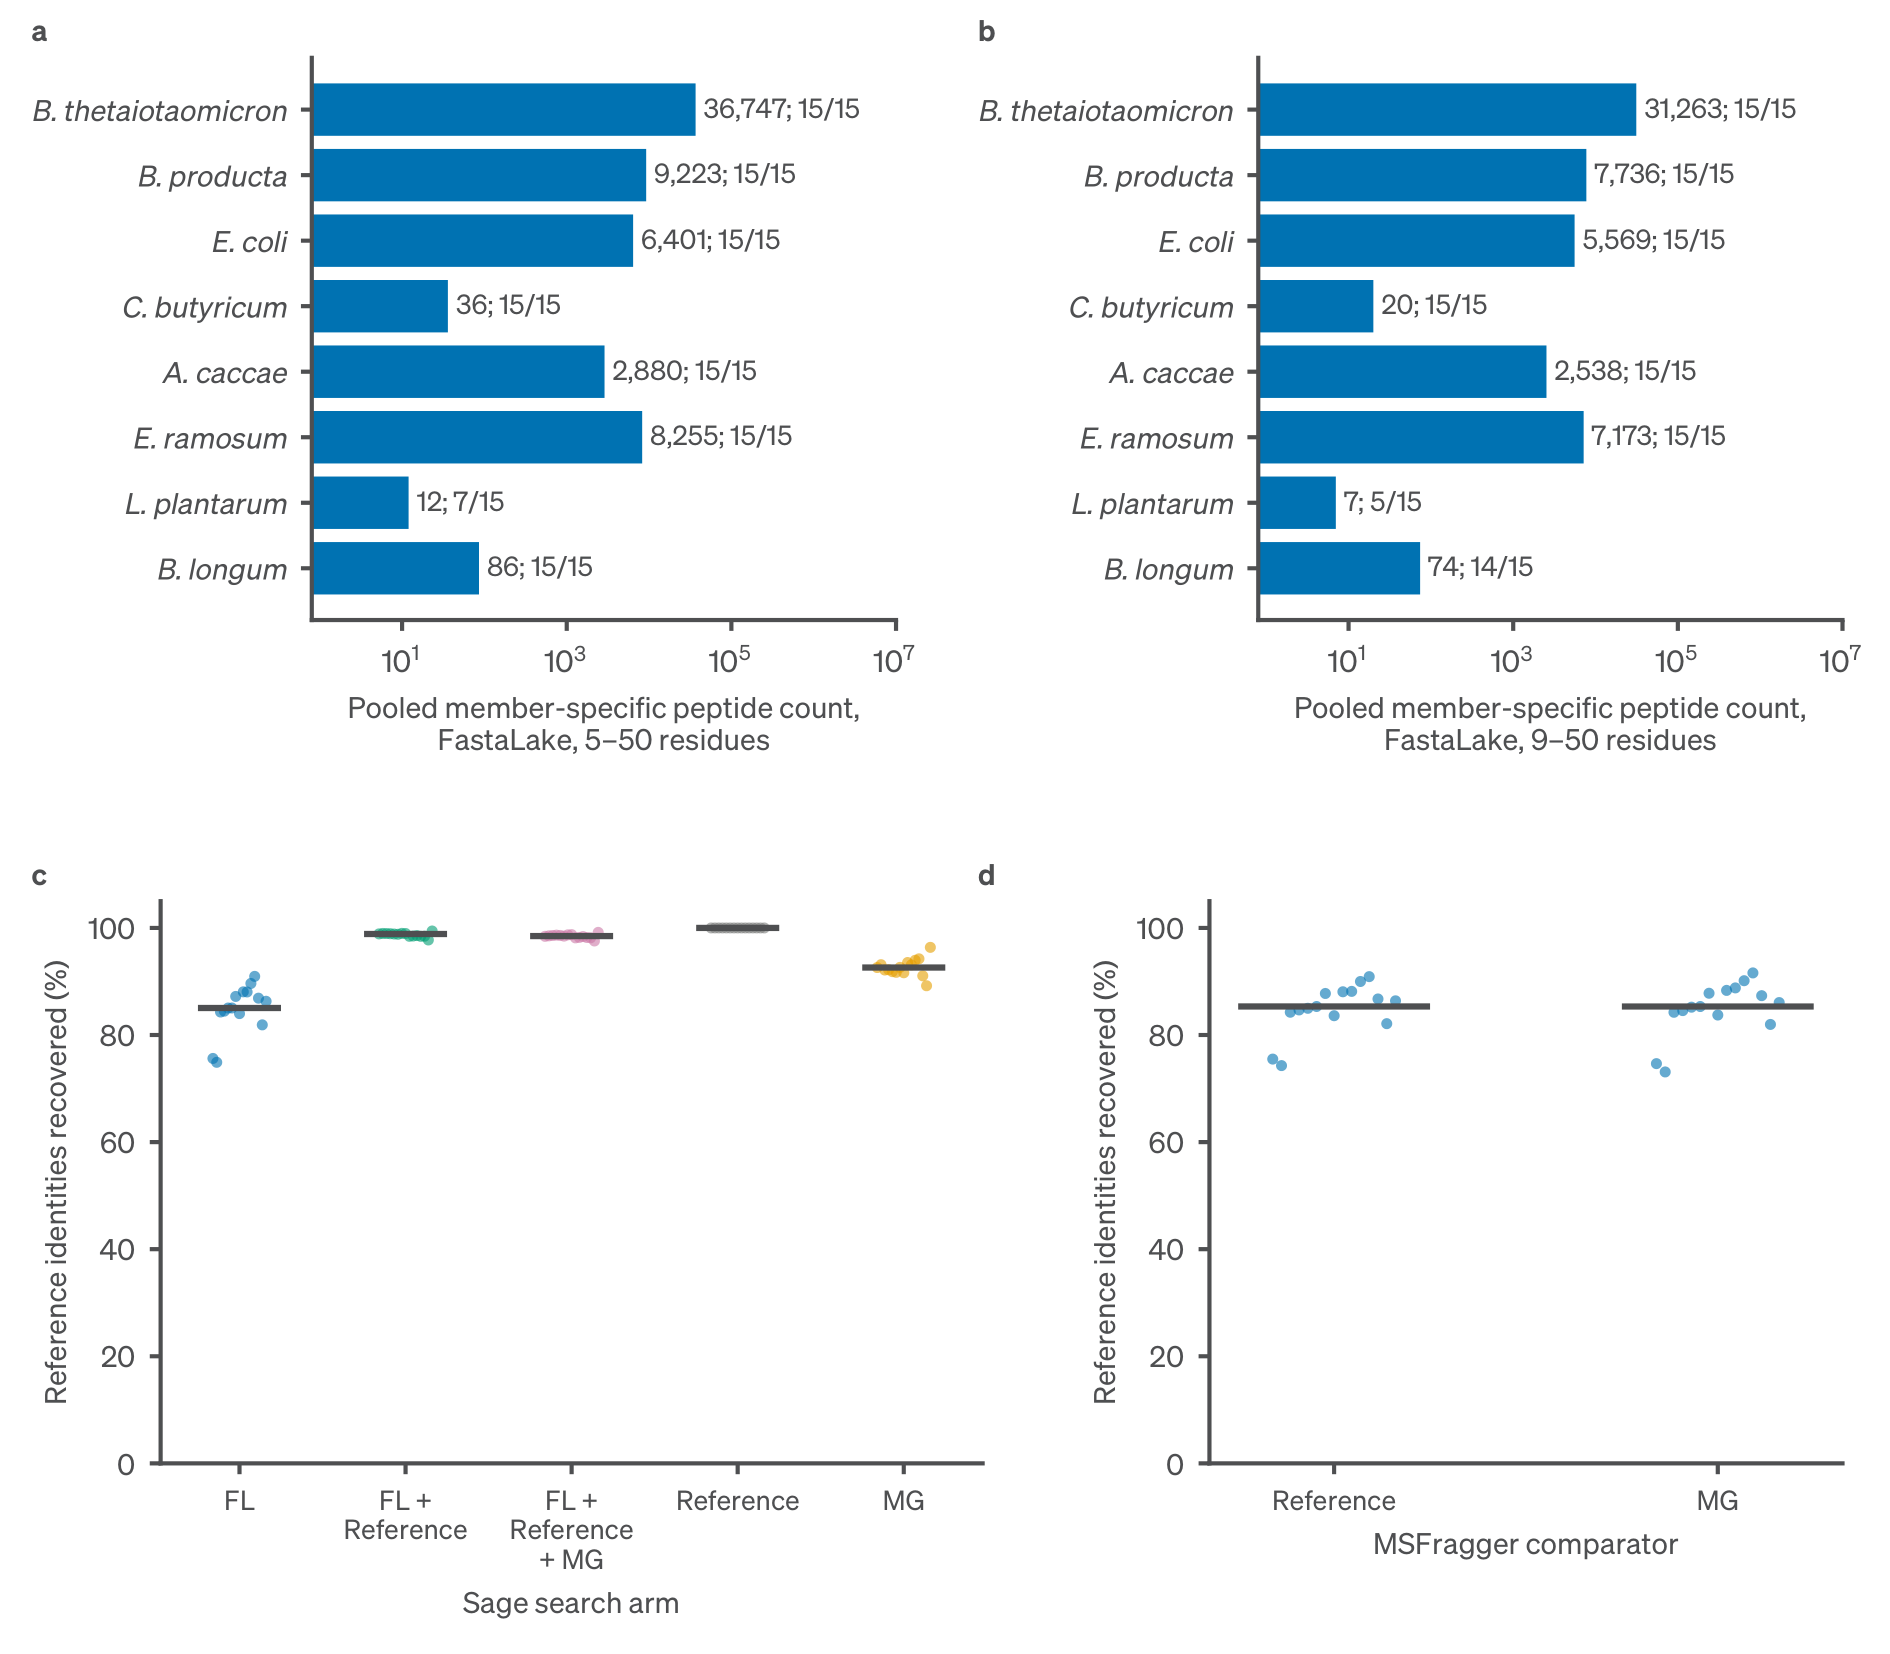

In [7]:
v30 = panels.build_v30(t, OUT)
print("v30 values identical:", v30["values_identical"], "| plotted table equal:", v30["plotted_table_equal_to_producer"], "| value labels equal:", v30["value_labels_equal"])
print("label strings lost (titles only):", v30["label_strings_lost"], "| slanted labels:", v30["slanted"], "| png px:", v30["png_px"])
display(Image(filename=str(v30["png"]), width=760))


## Checks and numbers

Pixel checks: the producer step (composite PDF at 300 dpi) against the len950 producer PDF (`expected/SFig03_len950.pdf`), and the v30 house-style PNG against the v30 figure (`expected/SFig03_v30.png`, 300 dpi). Then the plotted values are compared with the len950 producer's plotted-values table, and every number of `NUMBERS.tsv` is printed in row order.

In [8]:
import json
from tools.check_pixels import compare
EXP, CHK = UNIT / "expected", UNIT / "checks"
if HAVE_FONT:
    checks = {"len950_pdf_300dpi": compare(res["pdf"], EXP / "SFig03_len950.pdf", CHK / "SFig03_len950", dpi=300),
              "SFig03_v30": compare(v30["png"], EXP / "SFig03_v30.png", CHK / "SFig03_v30", dpi=300)}
    for k, r in checks.items():
        print(f"{k:22s} {r['verdict']:10s} differing pixels: {r.get('differing_pixels')}")
else:
    print("pixel checks SKIPPED: fonts absent")

exp_pv = pd.read_csv(EXP / "plotted_values.tsv", sep="\t", keep_default_na=False, dtype=str)
new_pv = pd.read_csv(OUT / "plotted_values.tsv", sep="\t", keep_default_na=False, dtype=str)
cols = ["panel", "group", "arm", "min_length", "sample", "acquisitions_with_support", "label", "source"]
same_text = exp_pv[cols].equals(new_pv[cols])
num_diff = max(abs(float(a) - float(b)) for c in ("x", "value") for a, b in zip(exp_pv[c], new_pv[c]))
print("plotted values: text columns identical:", same_text, "| max numeric difference:", num_diff)
assert same_text and num_diff == 0

for label, value in panels.recomputed_numbers(t, s83, s89, rcpt):
    print(f"{label}\t{value!r}")

len950_pdf_300dpi      IDENTICAL  differing pixels: 0
SFig03_v30             IDENTICAL  differing pixels: 0
plotted values: text columns identical: True | max numeric difference: 0.0
83 members with FL member-specific peptides	'eight'
83 L. plantarum FL pooled 5-50	'twelve'
83 lower length bound	5
83 upper length bound	50
83 L. plantarum FL pooled 9-50	'seven'
83 nested lower length bound	9
83 upper length bound	50
83 MG members with member-specific peptides at 9-50	'six'
83 nested lower length bound	9
83 upper length bound	50
83 REF/FL fold, least of three members (5-50)	3.372093023255814
83 REF/FL fold, most of three members (5-50)	16.75
89 median FL/REF count ratio	1.0028744939271257
89 median FL/MG count ratio	0.9444444444444444
89 median comparator identity recovery (%)	85.32740574999751
253 CAMPI acquisitions searched	15
253 MSFragger version	'4.1'
253 Percolator version	'3.06.5'
417 acquisitions denominator	15
417 reference proteomes	'eight'
417 nested lower length bound	9
417 u